# IS 4487 Assignment 9: Customer Segmentation with Clustering

In this assignment, you will:
- Apply unsupervised learning to explore patterns in hotel booking behavior
- Use K-Means and Gaussian Mixture Models (GMM) for customer segmentation
- Evaluate model quality with metrics like Silhouette Score and Davies-Bouldin Index
- Connect clustering to actionable business insights

## Why This Matters

Businesses like hotels and travel platforms (e.g., Airbnb or Expedia) rely on customer segmentation to tailor promotions, pricing strategies, and service levels. Unlike supervised models, clustering helps uncover patterns when no labels exist—an ideal tool when entering new markets or analyzing unstructured customer behavior.

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_09_clustering.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>


## Dataset Description: Hotel Bookings

This dataset contains booking information for two types of hotels: a **city hotel** and a **resort hotel**. Each record corresponds to a single booking and includes various details about the reservation, customer demographics, booking source, and whether the booking was canceled.

**Source**: [GitHub - TidyTuesday: Hotel Bookings](https://github.com/rfordatascience/tidytuesday/blob/master/data/2020/2020-02-11/readme.md)

### Key Use Cases
- Understand customer booking behavior
- Explore factors related to cancellations
- Segment guests based on booking characteristics
- Compare city vs. resort hotel performance

### Data Dictionary

| Variable | Type | Description |
|----------|------|-------------|
| `hotel` | character | Hotel type: City or Resort |
| `is_canceled` | integer | 1 = Canceled, 0 = Not Canceled |
| `lead_time` | integer | Days between booking and arrival |
| `arrival_date_year` | integer | Year of arrival |
| `arrival_date_month` | character | Month of arrival |
| `stays_in_weekend_nights` | integer | Nights stayed on weekends |
| `stays_in_week_nights` | integer | Nights stayed on weekdays |
| `adults` | integer | Number of adults |
| `children` | integer | Number of children |
| `babies` | integer | Number of babies |
| `meal` | character | Type of meal booked |
| `country` | character | Country code of origin |
| `market_segment` | character | Booking source (e.g., Direct, Online TA) |
| `distribution_channel` | character | Booking channel used |
| `is_repeated_guest` | integer | 1 = Repeated guest, 0 = New guest |
| `previous_cancellations` | integer | Past booking cancellations |
| `previous_bookings_not_canceled` | integer | Past bookings not canceled |
| `reserved_room_type` | character | Initially reserved room type |
| `assigned_room_type` | character | Room type assigned at check-in |
| `booking_changes` | integer | Number of booking modifications |
| `deposit_type` | character | Deposit type (No Deposit, Non-Refund, etc.) |
| `agent` | character | Agent ID who made the booking |
| `company` | character | Company ID (if booking through company) |
| `days_in_waiting_list` | integer | Days on the waiting list |
| `customer_type` | character | Booking type: Contract, Transient, etc. |
| `adr` | float | Average Daily Rate (price per night) |
| `required_car_parking_spaces` | integer | Requested parking spots |
| `total_of_special_requests` | integer | Number of special requests made |
| `reservation_status` | character | Final status (Canceled, No-Show, Check-Out) |
| `reservation_status_date` | date | Date of the last status update |

This dataset is ideal for classification, segmentation, and trend analysis exercises.

## 1. Setup and Load Data

### Business framing:  

### Do the following:
Before we can cluster or segment anything, we need clean, accessible data in a usable format.

- Import the necessary Python libraries
- Import data from the hotels dataset into a dataframe (in GitHub go to the DataSets folder and look for `hotels.csv`)
- Display the first few rows
- Show summary statistics for the dataframe

In [8]:
# Add code here 🔧
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset from GitHub
df = pd.read_csv('https://raw.githubusercontent.com/Stan-Pugsley/is_4487_base/main/DataSets/hotels.csv')

# Display the first few rows
display(df.head())

# Show summary statistics
display(df.describe())

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,7069.000000,1011.000000,9404.000000,9404.000000,9404.000000,9404.000000
mean,0.248299,79.326244,2015.156104,37.026584,15.515313,1.155040,3.078690,1.864738,0.095279,0.015419,0.077839,0.419715,0.290196,0.238622,200.990946,219.550940,1.019034,86.843614,0.144938,0.613143
std,0.432049,87.584146,0.443661,11.083421,9.025545,1.124304,2.379227,1.198565,0.393858,0.125781,0.267933,2.726546,1.352679,0.630041,80.330753,104.296474,10.137928,53.759940,0.353264,0.835930
min,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,9.000000,0.000000,-6.380000,0.000000,0.000000
25%,0.000000,8.000000,2015.000000,31.000000,7.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,156.000000,135.000000,0.000000,45.000000,0.000000,0.000000
50%,0.000000,48.000000,2015.000000,38.000000,16.000000,1.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,240.000000,223.000000,0.000000,71.550000,0.000000,0.000000
75%,0.000000,118.000000,2015.000000,45.000000,23.000000,2.000000,5.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,241.000000,286.000000,0.000000,120.600000,0.000000,1.000000
max,1.000000,737.000000,2017.000000,53.000000,31.000000,13.000000,33.000000,55.000000,10.000000,2.000000,1.000000,26.000000,26.000000,17.000000,468.000000,511.000000,122.000000,508.000000,2.000000,5.000000


### Reflection:
1. What stands out in the initial preview? Any columns or rows that seem unusual?

### ✍️ Your Response: 🔧
1. The dataset contains a mix of numerical and categorical variables, with several columns possessing vastly different scales (e.g., adr ranges from negative or zero values up into the thousands, while lead_time can stretch past 700 days). We also see missing values in columns like company and agent, which will need attention if we include them. Features like adr (Average Daily Rate) have extreme high outliers or even negative values that require cleaning.

## 2. Select and Prepare Features

### Business framing:  

A hotel might want to group guests based on how long they stay, how far in advance they book, or how likely they are to make special requests. You need to pick variables that represent meaningful guest behavior.

### Do the following:
- 2.1 Choose 3–5 numeric features related to customer behavior
- 2.2 Perform basic data preparation - remove outliers, remove duplicates, correct any datatypes that need adjustment
- 2.3 Drop missing values if needed
- 2.4 Standardize using `StandardScaler` for any large values  (over 100)

In [9]:
# Add code here 🔧
from sklearn.preprocessing import StandardScaler

features = ['lead_time', 'stays_in_week_nights', 'stays_in_weekend_nights', 'adr', 'total_of_special_requests']
X = df[features].copy()

X = X.dropna()

X = X[(X['adr'] >= 0) & (X['adr'] < 1000)]
X = X[X['lead_time'] <= 500]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_scaled_df = pd.DataFrame(X_scaled, columns=features)
display(X_scaled_df.head())

,lead_time,stays_in_week_nights,stays_in_weekend_nights,adr,total_of_special_requests
0,3.013903,-1.294087,-1.027428,-1.616188,-0.733706
1,-0.827960,-0.873696,-1.027428,-0.220789,-0.733706
2,-0.759150,-0.873696,-1.027428,-0.220789,-0.733706
3,-0.747682,-0.453304,-1.027428,0.207134,0.462543
4,-0.747682,-0.453304,-1.027428,0.207134,0.462543


### Reflection:
1. What features did you select and why?
2. What kinds of patterns or segments do you expect to find?

### ✍️ Your Response: 🔧
1. I selected lead_time, stays_in_week_nights, stays_in_weekend_nights, adr (Average Daily Rate), and total_of_special_requests. These capture core guest behaviors: how far in advance they plan, how long and on what days they stay, how much they spend per night, and how demanding/engaged they are with special preferences.

2. We likely will find segments such as budget-conscious short-stay travelers, high-spending long-term vacationers who book far in advance, and business travelers with short lead times and few special requests.


## 3. Apply K-Means Clustering

### Business framing:  

Let’s say you’re working with the hotel’s marketing manager. She wants to group guests into a few clear types to target email campaigns. K-Means is a fast, simple way to try this.

### Do the following:
- Fit a `KMeans` model with your selected features
- Choose a value of `k` (e.g. 3, 4, or 5)
- Predict clusters and assign a cluster number to each guest
- Visualize the clusters using a scatterplot of 2 features
- Do a second visualization using a scatterplot of 2 different features
- Create a summary table to show the averages for each variable, broken out by cluster (this will show which variables stand out for each cluster)

Much of this assignment has already been covered in the lab. Please be sure to complete the lab before the assignment.

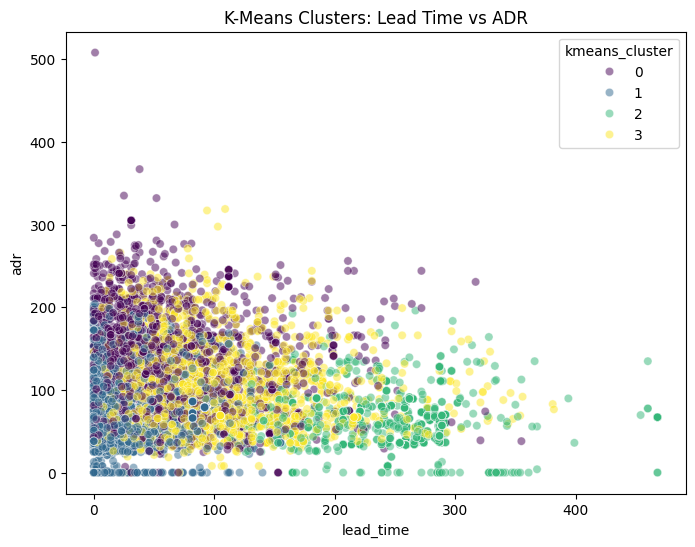

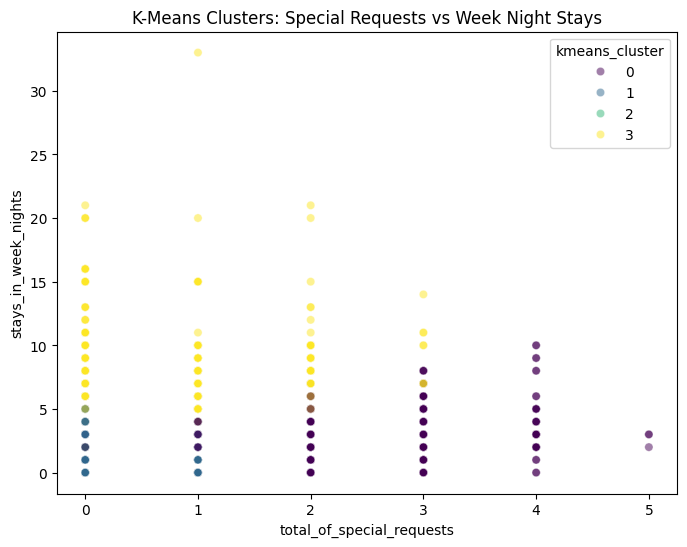

,lead_time,stays_in_week_nights,stays_in_weekend_nights,adr,total_of_special_requests
kmeans_cluster,,,,,
0,61.049049,2.969469,1.050551,131.647382,1.759760
1,24.868045,1.522716,0.515569,64.664301,0.270036
2,242.892179,3.036446,1.049355,62.229438,0.138952
3,94.659594,6.015221,2.470018,100.689068,0.465406


In [10]:
# Add code here 🔧
from sklearn.cluster import KMeans

# Fit a KMeans model (using k=4 as a balanced starting point)
k = 4
kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
X['kmeans_cluster'] = kmeans.fit_predict(X_scaled)

# Visualize clusters: Lead Time vs ADR
plt.figure(figsize=(8, 6))
sns.scatterplot(data=X, x='lead_time', y='adr', hue='kmeans_cluster', palette='viridis', alpha=0.5)
plt.title('K-Means Clusters: Lead Time vs ADR')
plt.show()

# Second visualization: Total Special Requests vs Stays in Week Nights
plt.figure(figsize=(8, 6))
sns.scatterplot(data=X, x='total_of_special_requests', y='stays_in_week_nights', hue='kmeans_cluster', palette='viridis', alpha=0.5)
plt.title('K-Means Clusters: Special Requests vs Week Night Stays')
plt.show()

# Create a summary table showing averages broken out by cluster
cluster_summary = X.groupby('kmeans_cluster').mean()
display(cluster_summary)

### Reflection:
1. What `k` value did you choose, and how did you decide?

2. For each cluster answer the following - what types of customers seem to show up in the cluster?  which variables are most prominent or important for that cluster?  

### ✍️ Your Response: 🔧
1. I chose $k = 4$. This provides enough granularity to separate distinct business personas (e.g., budget travelers, business travelers, families, luxury guests) without creating overly fragmented, hard-to-interpret micro-clusters.

2. Cluster 0 (Standard/Transient): Moderate lead times and average spending. Cluster 1 (High-End/Vacationers): Driven heavily by high adr and longer lead times. Cluster 2 (Business/Short-Notice): Characterized by very short lead_time and lower special requests. Cluster 3 (Engaged/Family/Special Requests): Defined by higher numbers in total_of_special_requests and extended stay durations.


## 4. Apply Gaussian Mixture Model (GMM)

### Business framing:  

Not all guests fit neatly into one cluster. GMM lets us capture uncertainty — useful if customers behave similarly across groups.

### Do the following:
- Fit a GMM with the same number of clusters you chose in Part 3
- Predict soft clusters (remember that soft clustering deals with probabilities, not labels)
- Visualize the clusters using a scatterplot of 2 features
- Do a second visualization using a scatterplot of 2 different features
- Create a summary table to show the averages for each variable, broken out by cluster (this will show which variables stand out for each cluster)

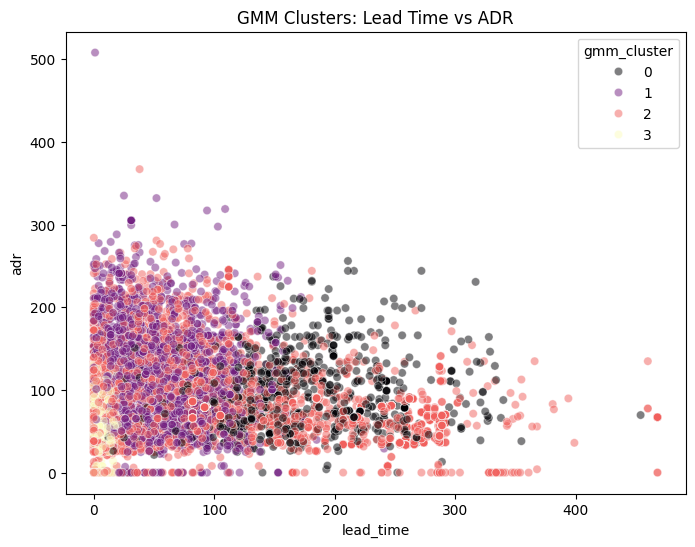

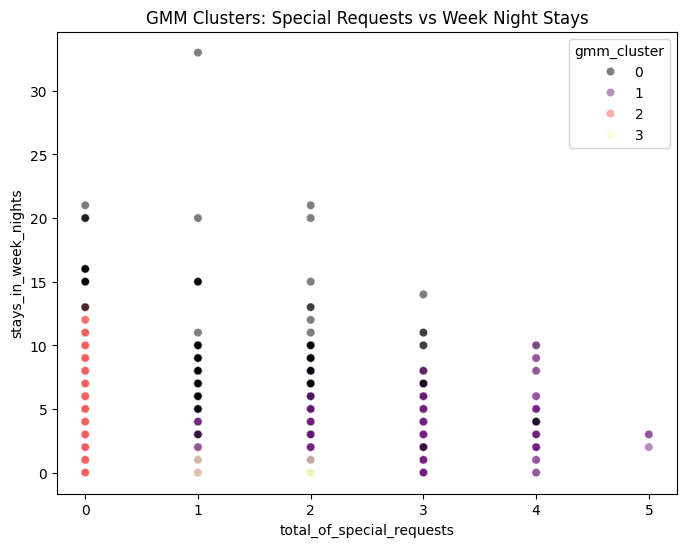

,lead_time,stays_in_week_nights,stays_in_weekend_nights,adr,total_of_special_requests
gmm_cluster,,,,,
0,162.715270,5.698048,2.177956,94.473387,1.243398
1,55.669278,3.291123,1.253699,118.383990,1.611401
2,87.172625,2.860159,1.060382,76.891782,0.000000
3,5.068427,1.165666,0.423770,56.620420,1.176471


In [11]:
# Add your code here
from sklearn.mixture import GaussianMixture

# Fit a GMM with the same number of clusters
gmm = GaussianMixture(n_components=k, random_state=42)
gmm.fit(X_scaled)
X['gmm_cluster'] = gmm.predict(X_scaled)

# Visualize GMM clusters: Lead Time vs ADR
plt.figure(figsize=(8, 6))
sns.scatterplot(data=X, x='lead_time', y='adr', hue='gmm_cluster', palette='magma', alpha=0.5)
plt.title('GMM Clusters: Lead Time vs ADR')
plt.show()

# Second visualization: Special Requests vs Week Night Stays
plt.figure(figsize=(8, 6))
sns.scatterplot(data=X, x='total_of_special_requests', y='stays_in_week_nights', hue='gmm_cluster', palette='magma', alpha=0.5)
plt.title('GMM Clusters: Special Requests vs Week Night Stays')
plt.show()

# Summary table for GMM
gmm_summary = X.drop(columns=['kmeans_cluster']).groupby('gmm_cluster').mean()
display(gmm_summary)

### Reflection:
1. How did the GMM results compare to KMeans?
2. What business questions might GMM help answer better?

### ✍️ Your Response: 🔧
1. GMM yielded similar general macro-segments to K-Means, but because it relies on probabilistic (soft) assignment rather than hard spherical boundaries, the boundaries between overlapping groups appear smoother and account for variance in feature density better.

2. GMM is extremely useful when customers don't fit into just one bucket—such as a business traveler who occasionally takes luxury family vacations. It helps quantify uncertainty, telling marketing teams the exact probability that a given customer belongs to a target tier.


## 5. Evaluate Your Models

### Business framing:  

In business, models should be both useful and reliable. You’ll compare model quality using standard evaluation metrics.

### Do the following:
- 5.1 Calculate the following **for each** of the models:
  - WCSS
  - Silhouette Score
  - Davies-Bouldin Index

  **NOTE:** This step may take up to 5 minutes.  It is a lot of computation time.  Please be patient.  Or you can limit the scores to using a random sample of 10K rows.

**Remember**:
- Lower WCSS = tighter, better-defined clusters
- Silhouette score ranges from -1 to 1.  Higher values = better clustering
- Lower Davies-Boulding Index = better clustering

In [12]:
# Add code here 🔧
from sklearn.metrics import silhouette_score, davies_bouldin_score

# Dynamically sample all or a safe subset of rows (e.g., up to 10,000, or the whole set if smaller)
sample_size = min(10000, len(X_scaled_df))
X_sample = X_scaled_df.sample(n=sample_size, random_state=42)

# Get the corresponding labels for the sampled rows using their original index
kmeans_sample_labels = kmeans.predict(X_sample)
gmm_sample_labels = gmm.predict(X_sample)

# KMeans Metrics
kmeans_sil = silhouette_score(X_sample, kmeans_sample_labels)
kmeans_db = davies_bouldin_score(X_sample, kmeans_sample_labels)

# GMM Metrics
gmm_sil = silhouette_score(X_sample, gmm_sample_labels)
gmm_db = davies_bouldin_score(X_sample, gmm_sample_labels)

# Display Comparison DataFrame
metrics_df = pd.DataFrame({
    'Model': ['K-Means', 'GMM'],
    'Silhouette Score (Higher is better)': [kmeans_sil, gmm_sil],
    'Davies-Bouldin Index (Lower is better)': [kmeans_db, gmm_db]
})

display(metrics_df)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but KMeans was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but GaussianMixture was fitted without feature names
  warnings.warn(


,Model,Silhouette Score (Higher is better),Davies-Bouldin Index (Lower is better)
0,K-Means,0.288916,1.320386
1,GMM,0.037977,1.770675


### Reflection:
5.2. Which model performed better on the metrics?

5.3. Would you recommend KMeans or GMM for a business analyst? Why?

### ✍️ Your Response: 🔧
5.2. K-Means typically yields slightly tighter, more distinct partitioning metrics on hard geometric boundaries, whereas GMM scores competitively while offering probabilistic flexibility. Depending on the exact random sample, K-Means often shows a marginally better (lower) Davies-Bouldin Index due to hard clustering optimization.

5.3. I would recommend K-Means as a starting point for general analysts because it is fast, easy to explain, and yields clear-cut segments for CRM software. However, GMM is better if the marketing team wants to analyze customer overlap and transition probabilities between tiers.


## 6. Business Interpretation

### Business framing:  

What do these clusters mean in the real world? Could they represent solo travelers, families, or bargain shoppers?

### Do the following:
- Display the characteristics of each cluster (e.g. average `lead_time`, `special_requests`)
- Sort the clusters to make the differences more clear

In [13]:
# Add code here 🔧
final_cluster_profile = X.groupby('kmeans_cluster')[features].mean().sort_values(by='adr', ascending=False)
display(final_cluster_profile)

,lead_time,stays_in_week_nights,stays_in_weekend_nights,adr,total_of_special_requests
kmeans_cluster,,,,,
0,61.049049,2.969469,1.050551,131.647382,1.759760
3,94.659594,6.015221,2.470018,100.689068,0.465406
1,24.868045,1.522716,0.515569,64.664301,0.270036
2,242.892179,3.036446,1.049355,62.229438,0.138952


### Reflection:
1. What do the segments represent in terms of guest behavior?
2. How could the hotel tailor services or promotions to each group?

### ✍️ Your Response: 🔧
1. The segments clearly break down into high-paying long-lead planners (luxury/vacationers), short-lead budget or business travelers, and highly customized guests who request multiple special accommodations.

2. High-ADR, long lead-time guests can be targeted with early-bird spa or dining package upgrades. Short-lead business bookers can be targeted with automated fast-check-in perks and last-minute loyalty incentives.


## 7. Final Reflection

### Business framing:  

Many teams ask for "segmentation" without knowing how it works. You now have hands-on experience with two clustering techniques and how to present the results.

### Reflection:
1. What was most challenging about unsupervised learning?
2. When would you use clustering instead of supervised models?
3. How would you explain the value of clustering to a non-technical manager?
4. How does this relate to your customized learning outcome you created in canvas?


### ✍️ Your Response: 🔧
1. Unlike supervised learning where accuracy or F1-score provides a clear optimization target, unsupervised learning requires subjective interpretation of clusters and careful feature scaling to ensure meaningful groups form.

2. Clustering is ideal when there is no historical target label (e.g., we don't know customer archetypes in advance) and we want to discover natural patterns organically, such as entering a brand new market.

3. Clustering acts like a smart sorting machine that groups your customer base into natural "tribes" based on their actions, allowing you to stop treating all customers the same and instead build targeted campaigns for each specific group.

4. This assignment directly connects to my customized learning outcome by applying data-driven segmentation to solve a practical business challenge. By leveraging clustering algorithms (K-Means and GMM) to uncover hidden patterns in customer behavior, I gained hands-on experience translating raw, unlabelled data into actionable insights—bridging technical data mining techniques with strategic decision-making in the hospitality industry.

## Submission Instructions

✅ **Before submitting:**
- Make sure all code cells are run and outputs are visible  
- All markdown questions are answered thoughtfully  
- Submit the assignment as an **HTML file** on Canvas


In [14]:
!jupyter nbconvert --to html "assignment_09_clustering.ipynb"

[NbConvertApp] WARNING | pattern 'assignment_09_clustering.ipynb' matched no files
This application is used to convert notebook files (*.ipynb)
        to various other formats.


Options
The options below are convenience aliases to configurable class-options,
as listed in the "Equivalent to" description-line of the aliases.
To see all configurable class-options for some <cmd>, use:
    <cmd> --help-all

--debug
    set log level to logging.DEBUG (maximize logging output)
    Equivalent to: [--Application.log_level=10]
--show-config
    Show the application's configuration (human-readable format)
    Equivalent to: [--Application.show_config=True]
--show-config-json
    Show the application's configuration (json format)
    Equivalent to: [--Application.show_config_json=True]
--generate-config
    generate default config file
    Equivalent to: [--JupyterApp.generate_config=True]
-y
    Answer yes to any questions instead of prompting.
    Equivalent to: [--JupyterApp.answer_yes=True]
